In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import ImageFolder
from torchvision.models import MobileNet_V2_Weights, mobilenet_v2
from torchvision.transforms import (
    Compose,
    Normalize,
    RandomHorizontalFlip,
    RandomRotation,
    Resize,
    ToTensor,
)

In [2]:
# Project paths
ROOT_DIR = Path.cwd().parent
DATA_DIR = ROOT_DIR / "Dataset"

# Training configuration
IMAGE_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 20
LEARNING_RATE = 1e-4
RANDOM_SEED = 42

torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

# Device configuration
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")

if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Working directory: {Path.cwd()}")
print(f"Project root: {ROOT_DIR}")
print(f"Dataset path: {DATA_DIR}")
print(f"Dataset exists: {DATA_DIR.exists()}")

PyTorch version: 2.14.1+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU
Working directory: c:\Users\varun\Documents\Uni\prsnl\Facemask-Detector\src
Project root: c:\Users\varun\Documents\Uni\prsnl\Facemask-Detector
Dataset path: c:\Users\varun\Documents\Uni\prsnl\Facemask-Detector\Dataset
Dataset exists: True


In [3]:
# Load the complete dataset for this image-level evaluation experiment.
dataset = ImageFolder(root=DATA_DIR)
labels = np.array(dataset.targets)
all_indices = np.arange(len(dataset))

print(f"Total images used: {len(dataset)}")
print(f"Classes: {dataset.classes}")
print(f"Class mapping: {dataset.class_to_idx}")

print("\nClass distribution:")
for class_name, class_index in dataset.class_to_idx.items():
    print(f"{class_name}: {np.sum(labels == class_index)}")


Total images used: 7553
Classes: ['with_mask', 'without_mask']
Class mapping: {'with_mask': 0, 'without_mask': 1}

Class distribution:
with_mask: 3725
without_mask: 3828


In [4]:
NORMALIZE = Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225],
)

preprocess = Compose([
    Resize((IMAGE_SIZE, IMAGE_SIZE)),
    ToTensor(),
    NORMALIZE,
])

train_transform = Compose([
    Resize((IMAGE_SIZE, IMAGE_SIZE)),
    RandomRotation(15),
    RandomHorizontalFlip(),
    ToTensor(),
    NORMALIZE,
])


In [5]:
# Create fixed stratified train, validation, and test splits.
train_val_indices, test_indices = train_test_split(
    all_indices,
    test_size=0.15,
    random_state=RANDOM_SEED,
    stratify=labels,
)

train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.15 / 0.85,
    random_state=RANDOM_SEED,
    stratify=labels[train_val_indices],
)

print(f"Training samples: {len(train_indices)}")
print(f"Validation samples: {len(val_indices)}")
print(f"Testing samples: {len(test_indices)}")
print("The test set is held out until final evaluation.")

Training samples: 5287
Validation samples: 1133
Testing samples: 1133
The test set is held out until final evaluation.


In [6]:
train_base_dataset = ImageFolder(root=DATA_DIR, transform=train_transform)
evaluation_base_dataset = ImageFolder(root=DATA_DIR, transform=preprocess)

train_dataset = Subset(train_base_dataset, train_indices)
val_dataset = Subset(evaluation_base_dataset, val_indices)
test_dataset = Subset(evaluation_base_dataset, test_indices)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Validation dataset size: {len(val_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

Training dataset size: 5287
Validation dataset size: 1133
Test dataset size: 1133


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)
train_eval_loader = DataLoader(
    Subset(evaluation_base_dataset, train_indices),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
)

In [8]:
weights = MobileNet_V2_Weights.DEFAULT


def create_model():
    model = mobilenet_v2(weights=weights)

    for parameter in model.features.parameters():
        parameter.requires_grad = False

    model.classifier = nn.Sequential(
        nn.Linear(model.last_channel, 128),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(128, 2),
    )

    return model.to(DEVICE)


In [9]:
def train_model(model, loader, criterion, optimizer, device):
    model.train()
    model.features.eval()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        predictions = outputs.argmax(dim=1)
        running_loss += loss.item() * images.size(0)
        correct_predictions += (predictions == labels).sum().item()
        total_samples += labels.size(0)

    return running_loss / total_samples, correct_predictions / total_samples


In [10]:
def evaluate_model(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            predictions = outputs.argmax(dim=1)

            running_loss += loss.item() * images.size(0)
            correct_predictions += (predictions == labels).sum().item()
            total_samples += labels.size(0)

    return running_loss / total_samples, correct_predictions / total_samples


In [11]:
# Train one model and restore the checkpoint with the best validation result.
model = create_model()
optimizer = optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}
best_val_accuracy = -1.0
best_val_loss = float("inf")
best_epoch = 0
best_state = None

for epoch in range(EPOCHS):
    train_loss, train_accuracy = train_model(
        model, train_loader, criterion, optimizer, DEVICE
    )
    val_loss, val_accuracy = evaluate_model(
        model, val_loader, criterion, DEVICE
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if (
        val_accuracy > best_val_accuracy
        or (val_accuracy == best_val_accuracy and val_loss < best_val_loss)
    ):
        best_val_accuracy = val_accuracy
        best_val_loss = val_loss
        best_epoch = epoch + 1
        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train loss: {train_loss:.4f}, accuracy: {train_accuracy:.4%} | "
        f"Validation loss: {val_loss:.4f}, accuracy: {val_accuracy:.4%}"
    )

model.load_state_dict(best_state)
print(
    f"Restored best checkpoint from epoch {best_epoch}: "
    f"validation accuracy={best_val_accuracy:.4%}, "
    f"validation loss={best_val_loss:.4f}"
)

c:\Users\varun\Documents\Uni\.venv\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/20] | Train loss: 0.3360, accuracy: 91.0346% | Validation loss: 0.1027, accuracy: 98.6761%
Epoch [2/20] | Train loss: 0.0891, accuracy: 98.2221% | Validation loss: 0.0527, accuracy: 98.9409%
Epoch [3/20] | Train loss: 0.0563, accuracy: 98.6949% | Validation loss: 0.0388, accuracy: 99.1174%
Epoch [4/20] | Train loss: 0.0471, accuracy: 98.6571% | Validation loss: 0.0334, accuracy: 99.2939%
Epoch [5/20] | Train loss: 0.0416, accuracy: 98.8462% | Validation loss: 0.0305, accuracy: 99.2056%
Epoch [6/20] | Train loss: 0.0385, accuracy: 98.8462% | Validation loss: 0.0286, accuracy: 99.2056%
Epoch [7/20] | Train loss: 0.0356, accuracy: 98.8841% | Validation loss: 0.0294, accuracy: 99.2939%
Epoch [8/20] | Train loss: 0.0327, accuracy: 99.0354% | Validation loss: 0.0265, accuracy: 99.2056%
Epoch [9/20] | Train loss: 0.0282, accuracy: 99.1489% | Validation loss: 0.0271, accuracy: 99.2939%
Epoch [10/20] | Train loss: 0.0301, accuracy: 99.2056% | Validation loss: 0.0265, accuracy: 99.3822%

In [12]:
# Evaluate the restored best model on the training and validation sets, then test once.
train_loss, train_accuracy = evaluate_model(
    model, train_eval_loader, criterion, DEVICE
)
val_loss, val_accuracy = evaluate_model(
    model, val_loader, criterion, DEVICE
)
test_loss, test_accuracy = evaluate_model(
    model, test_loader, criterion, DEVICE
)

print(f"Training:   Loss={train_loss:.4f}, Accuracy={train_accuracy:.4%}")
print(f"Validation: Loss={val_loss:.4f}, Accuracy={val_accuracy:.4%}")
print(f"Test:       Loss={test_loss:.4f}, Accuracy={test_accuracy:.4%}")

Training:   Loss=0.0140, Accuracy=99.5082%
Validation: Loss=0.0244, Accuracy=99.3822%
Test:       Loss=0.0221, Accuracy=99.4704%


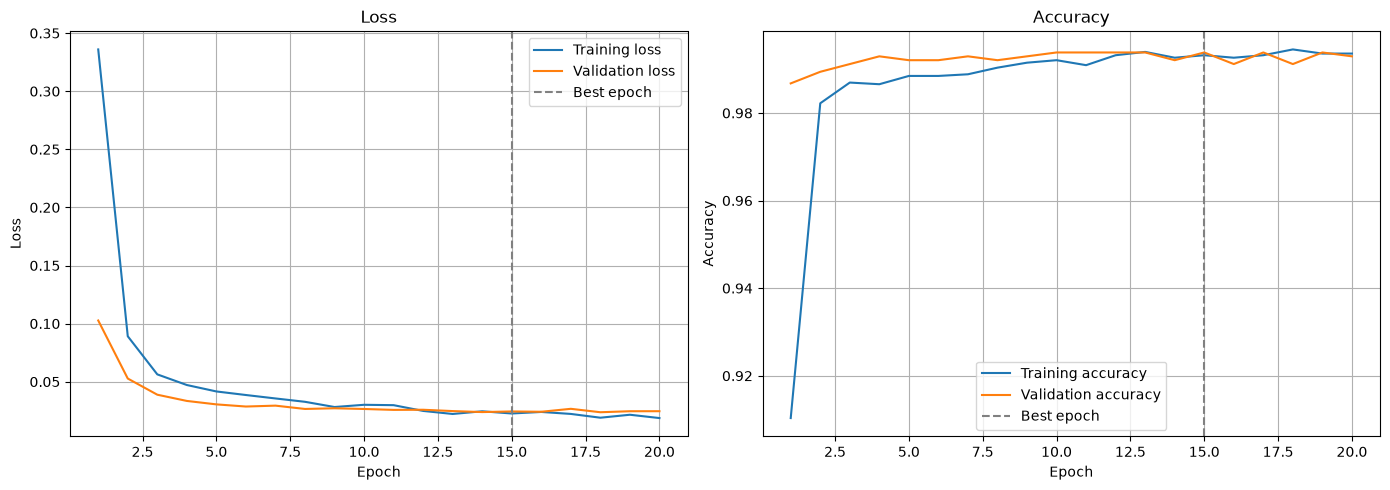

In [13]:
# Plot training and validation loss and accuracy.
epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"], label="Training loss")
axes[0].plot(epochs, history["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_accuracy"], label="Training accuracy")
axes[1].plot(epochs, history["val_accuracy"], label="Validation accuracy")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label="Best epoch")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

Test Classification Report:
              precision    recall  f1-score   support

   with_mask     0.9946    0.9946    0.9946       559
without_mask     0.9948    0.9948    0.9948       574

    accuracy                         0.9947      1133
   macro avg     0.9947    0.9947    0.9947      1133
weighted avg     0.9947    0.9947    0.9947      1133



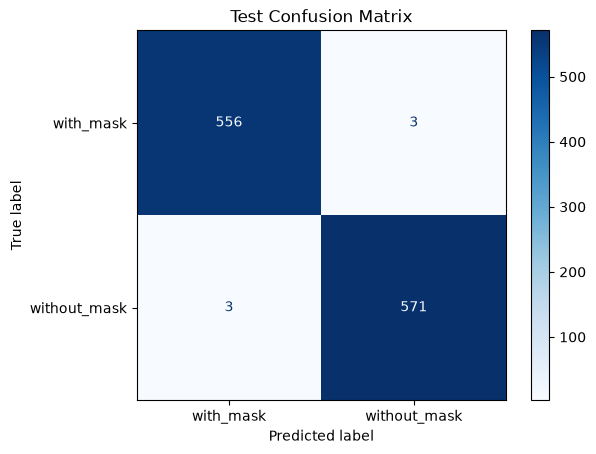

In [14]:
test_predictions = []
test_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(DEVICE)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(predictions.cpu().numpy())
        test_labels.extend(labels.numpy())

# Classification report
print("Test Classification Report:")
print(classification_report(
    test_labels,
    test_predictions,
    target_names=dataset.classes,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(test_labels, test_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=dataset.classes
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Test Confusion Matrix")
plt.show()

In [15]:
MODEL_DIR = ROOT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "mobilenetv2_full_dataset.pth"

torch.save(model.state_dict(), MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: c:\Users\varun\Documents\Uni\prsnl\Facemask-Detector\models\mobilenetv2_full_dataset.pth


In [16]:
experiment_metadata = {
    "experiment": "mobilenetv2_full_dataset_stratified_split",
    "model": "MobileNetV2",
    "pretrained": True,
    "backbone_frozen": True,
    "dataset": {
        "total_images": len(dataset),
        "classes": dataset.classes,
        "class_to_idx": dataset.class_to_idx,
    },
    "split": {
        "type": "image_level_stratified",
        "train_size": len(train_indices),
        "validation_size": len(val_indices),
        "test_size": len(test_indices),
        "random_seed": RANDOM_SEED,
        "test_fraction": 0.15,
        "validation_fraction": 0.15,
    },
    "training": {
        "batch_size": BATCH_SIZE,
        "max_epochs": EPOCHS,
        "best_epoch": best_epoch,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "loss": "CrossEntropyLoss",
    },
    "metrics": {
        "best_validation_accuracy": best_val_accuracy,
        "best_validation_loss": best_val_loss,
        "training_accuracy": train_accuracy,
        "validation_accuracy": val_accuracy,
        "test_accuracy": test_accuracy,
        "training_loss": train_loss,
        "validation_loss": val_loss,
        "test_loss": test_loss,
    },
    "original_dataset_modified": False,
}

METADATA_PATH = MODEL_DIR / "full_dataset_metadata.json"
with METADATA_PATH.open("w", encoding="utf-8") as file:
    json.dump(experiment_metadata, file, indent=4)

print(f"Metadata saved to: {METADATA_PATH}")

Metadata saved to: c:\Users\varun\Documents\Uni\prsnl\Facemask-Detector\models\full_dataset_metadata.json
